# Method 3: predict from similar players

**Question.** If a player with 150 minutes had played a full season, what would their numbers look like?

**Idea in plain words.** Players with a lot of minutes give us an answer key: we know their full-season rate.
We can *replay* their season as if they had only played 150 minutes (pick random matches until the minutes add up)
and record how the numbers looked at that point. That gives many examples of "what 150 minutes looked like"
paired with "what the full season turned out to be".
For a real 150-minute player, we find the replays that look most similar and average their full-season outcome.

**Plan.** 1) build the replays, 2) check they behave sensibly (noise falls as minutes grow),
3) look at one player's neighbours, 4) score on next season.

In [1]:
import sys
sys.path.append("..")  # so we can import the analysis/ folder from the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from analysis import common
from analysis import similar_player_prediction as sp
sns.set_theme(style="whitegrid", context="notebook")

GENDER, ROLE = "female", "FW"   # the player pool for every experiment
STAT = "goals"                  # the stat we zoom in on in plots

con = common.connect()
terms = common.load_player_terms(con, GENDER, ROLE)          # one row per player-season
pairs = common.make_next_year_pairs(terms, ROLE)             # season t paired with season t+1
raw, target, minutes = common.split_pairs(pairs, ROLE)       # raw per-90, next-year per-90, minutes
all_rates = common.per90(terms, ROLE)                        # per-90 for every player-season
print(f"{len(terms):,} player-seasons, {len(pairs):,} with a usable next season")

5,941 player-seasons, 1,726 with a usable next season


In [2]:
matches = common.load_player_matches(con, GENDER, ROLE)
print(f"{len(matches):,} player-matches loaded")
sim = sp.simulate_low_minutes(matches, ROLE)
print(f"{len(sim):,} replays from {sim['player_id'].nunique():,} players")
sim.head()

181,657 player-matches loaded


268,032 replays from 2,393 players


,player_id,year,minutes,part_goals,part_xg_shot,part_shots,part_shots_on_target,part_assists,part_xg_assist,part_key_passes,...,full_goals,full_xg_shot,full_shots,full_shots_on_target,full_assists,full_xg_assist,full_key_passes,full_touch_in_box,full_successful_dribbles,full_offensive_duels_won
0,57396,2021,134.0,0.000000,0.497015,4.701493,1.343284,0.0,0.275373,0.671642,...,0.323508,0.347448,2.393961,1.035226,0.064702,0.128109,0.258807,2.717469,2.717469,3.687994
1,57396,2021,128.0,0.000000,0.175781,3.515625,1.406250,0.0,0.014063,0.000000,...,0.323508,0.347448,2.393961,1.035226,0.064702,0.128109,0.258807,2.717469,2.717469,3.687994
2,57396,2021,77.0,1.168831,0.327273,2.337662,1.168831,0.0,0.000000,0.000000,...,0.323508,0.347448,2.393961,1.035226,0.064702,0.128109,0.258807,2.717469,2.717469,3.687994
3,57396,2021,99.0,0.909091,0.654545,0.909091,0.909091,0.0,0.081818,0.000000,...,0.323508,0.347448,2.393961,1.035226,0.064702,0.128109,0.258807,2.717469,2.717469,3.687994
4,57396,2021,101.0,0.000000,0.294059,2.673267,0.891089,0.0,0.000000,0.000000,...,0.323508,0.347448,2.393961,1.035226,0.064702,0.128109,0.258807,2.717469,2.717469,3.687994


## 1. Do the replays make sense?

For four players with a full-season goals/90 spread from low to high we draw their replayed goals/90 at each minute level.
The horizontal line is the full-season rate. Replays should scatter widely at low minutes and tighten around the line as minutes grow.

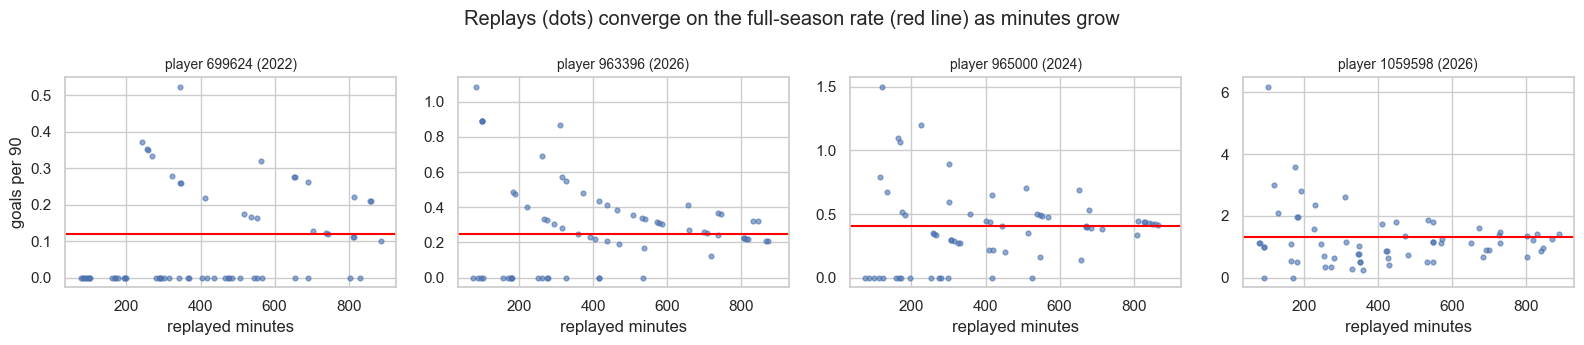

In [3]:
full = sim.groupby(["player_id", "year"])[f"full_{STAT}"].first().sort_values()
picks = full.iloc[np.linspace(len(full) * 0.3, len(full) - 1, 4).astype(int)].index

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharex=True)
for ax, (player_id, year) in zip(axes, picks):
    rows_ = sim[(sim["player_id"] == player_id) & (sim["year"] == year)]
    ax.scatter(rows_["minutes"], rows_[f"part_{STAT}"], s=12, alpha=0.6)
    ax.axhline(full[(player_id, year)], color="red")
    ax.set_title(f"player {player_id} ({year})", fontsize=10); ax.set_xlabel("replayed minutes")
axes[0].set_ylabel(f"{STAT} per 90")
plt.suptitle("Replays (dots) converge on the full-season rate (red line) as minutes grow")
plt.tight_layout(); plt.show()

The same idea over all players: how far is a replay from the full-season rate, on average?
This is the **learning curve** of the data: it shows how many minutes it takes before the raw number is trustworthy.

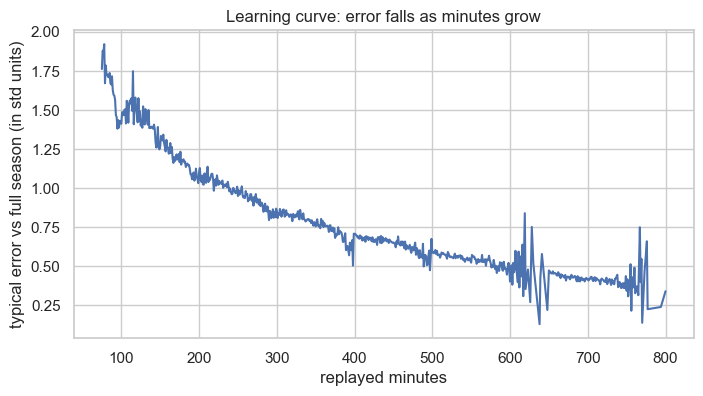

In [4]:
stats = common.STAT_COLS[ROLE]
spread = sim[[f"full_{s}" for s in stats]].std().to_numpy()
error = (sim[[f"part_{s}" for s in stats]].to_numpy() - sim[[f"full_{s}" for s in stats]].to_numpy()) / spread
sim["error"] = np.sqrt((error ** 2).mean(axis=1))

fig, ax = plt.subplots(figsize=(8, 4))
# Replays are built to stop near their target, so past ~800 minutes there is too little data to plot.
sns.lineplot(data=sim[sim["minutes"] <= 800].sort_values("minutes"), x="minutes", y="error", ax=ax, errorbar=None)
ax.set_xlabel("replayed minutes"); ax.set_ylabel("typical error vs full season (in std units)")
ax.set_title("Learning curve: error falls as minutes grow")
plt.show()

## 2. One player, up close

We pick a low-minute player and look at the replays the model considers most similar.
The bars compare (in standard deviations from the average) the player's raw per-90, the neighbours' average full-season outcome (our prediction) and what the player actually did the next year.

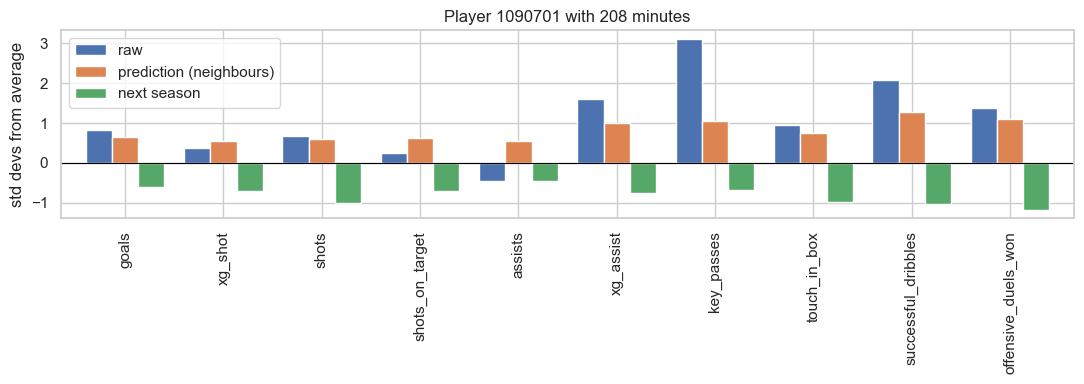

In [5]:
models = sp.fit_models(sim, ROLE)
low_rows = pairs.index[(minutes >= 150) & (minutes < 250)]
example = low_rows[0]

bin_ = pd.cut(pd.Series([minutes[example]]), sp.BIN_EDGES, right=False)[0]
scaler, knn = models[bin_]
vector = scaler.transform(raw.loc[[example]].to_numpy())
distances, neighbor_idx = knn.kneighbors(vector)
neighbors = knn.predict(vector)[0]

mean, std = all_rates.mean(), all_rates.std()
view = pd.DataFrame({"raw": (raw.loc[example] - mean) / std,
                     "prediction (neighbours)": (neighbors - mean) / std,
                     "next season": (target.loc[example] - mean) / std})
view.plot.bar(figsize=(11, 4), width=0.8)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("std devs from average")
plt.title(f"Player {pairs.loc[example, 'player_id']} with {minutes[example]:.0f} minutes")
plt.tight_layout(); plt.show()

## 3. Score on next season

Predictions come from `cross_fitted_predict`: players are split into folds and each fold is predicted by models
that never saw those players, so nobody helps predict themselves.

In [6]:
folds_check = sp.cross_fitted_predict(sim, raw, minutes, pairs["player_id"], ROLE)
folds_check.head(3)

,goals,xg_shot,shots,shots_on_target,assists,xg_assist,key_passes,touch_in_box,successful_dribbles,offensive_duels_won
0,0.321473,0.197768,1.728666,0.866143,0.032000,0.041582,0.145299,2.443336,2.675204,4.344036
1,0.081874,0.101189,0.938989,0.327123,0.029944,0.037816,0.122586,1.344904,2.066178,3.908323
2,0.059055,0.106299,1.653543,0.767717,0.118110,0.075591,0.413386,2.244094,1.889764,2.775591


In [7]:
def plot_scores(results: dict):
    """Bar charts of RMSE (lower is better) and Spearman (higher is better) per minute bucket."""
    table = pd.concat(results, names=["method"]).reset_index()
    table = table[table["bucket"] != "all"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric, title in zip(axes, ["rmse", "spearman"],
                                 ["RMSE vs next season (lower is better)",
                                  "Spearman vs next season (higher is better)"]):
        sns.barplot(data=table, x="bucket", y=metric, hue="method", ax=ax)
        ax.set_title(title)
        ax.set_xlabel("Minutes played in season t")
    plt.tight_layout()
    plt.show()

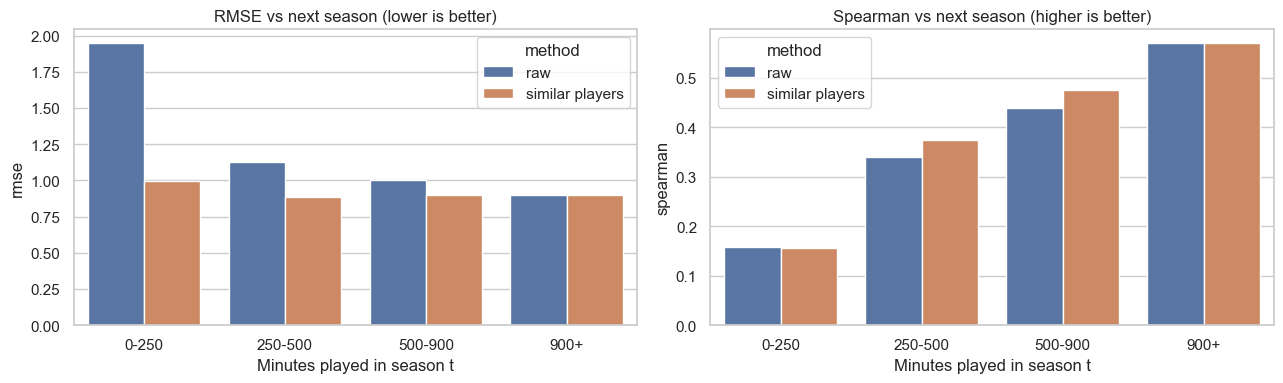

n  spearman   rmse
method          bucket                        
raw             all      1726     0.450  1.150
                0-250     222     0.157  1.945
                250-500   245     0.341  1.127
                500-900   479     0.438  1.004
                900+      780     0.569  0.902
similar players all      1726     0.474  0.914
                0-250     222     0.157  0.995
                250-500   245     0.375  0.888
                500-900   479     0.474  0.900
                900+      780     0.569  0.902

In [8]:
results = {"raw": common.evaluate(raw, target, minutes),
           "similar players": common.evaluate(folds_check, target, minutes)}
plot_scores(results)
pd.concat(results, names=["method"]).round(3)

### Calibration

For players under 500 minutes we split them into groups by their estimate and compare the group's average estimate
with the group's average next-season result. Points on the dashed line mean the estimates are on the right scale.

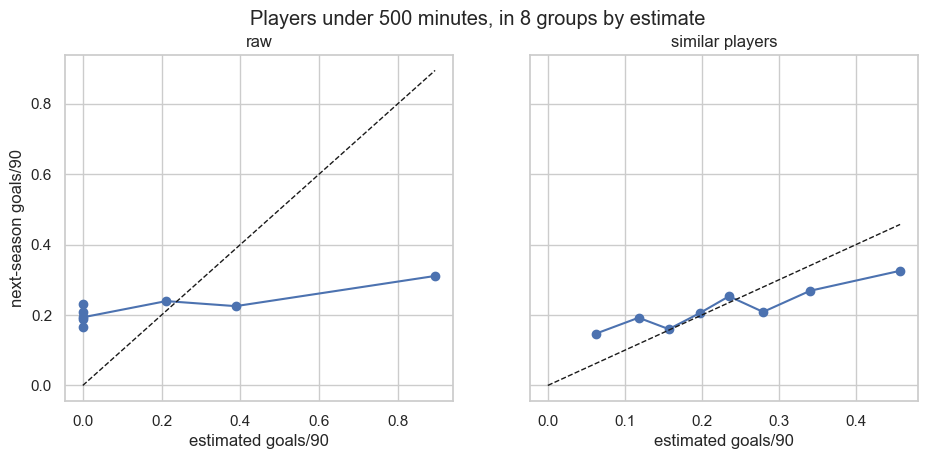

In [9]:
short = minutes < 500
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, est) in zip(axes, [("raw", raw), ("similar players", folds_check)]):
    groups = pd.qcut(est.loc[short, STAT].rank(method="first"), 8, labels=False)
    avg = pd.DataFrame({"estimate": est.loc[short, STAT], "next season": target.loc[short, STAT]}).groupby(groups).mean()
    ax.plot(avg["estimate"], avg["next season"], "o-")
    top = max(avg.max())
    ax.plot([0, top], [0, top], "k--", linewidth=1)
    ax.set_title(name); ax.set_xlabel(f"estimated {STAT}/90")
axes[0].set_ylabel(f"next-season {STAT}/90")
plt.suptitle("Players under 500 minutes, in 8 groups by estimate")
plt.show()

## Takeaways

* The learning curve shows why raw numbers fail at low minutes and gives a feel for how long it takes to trust them.
* This method uses every stat at once and learns from real players, so it is the most flexible of the three.
* Limits: the replays pick matches at random, but a real low-minute player often comes off the bench in the later part
  of games, so their situation may differ from the replays. Each replay is part of the season it is predicting,
  which makes the full-season label slightly easier than a truly future one.